# Study 01 — Differential Evolution (DE)

Exploratory study notebook: before wiring DE into the full experiment system, we check that it works,
learn how its hyper-parameters behave on our tuning problem, and see how it copes with every controller and plant.

**Questions**
1. Does the implementation actually optimise? (benchmark functions with known optimum)
2. Which hyper-parameters matter for controller tuning, and how much?
3. With a fixed evaluation budget, is it better to have a big population or many generations?
4. How well does it tune each controller on each plant — and where does it fail?

All runs use the project's own simulator, metrics and objective through
`smart_control.experiments.runner.run_single_experiment`. Only `numpy`, `matplotlib` and `control` are used.
⏱ Full run: about 5 minutes on a laptop.

## The algorithm

**Idea.** Every generation, each member $x_i$ gets a *mutant* built from three other members,
$$v = x_{r_1} + F\,(x_{r_2}-x_{r_3}),$$
then a binomial crossover mixes mutant and parent gene-by-gene with probability $CR$,
and the trial replaces the parent only if it is better (greedy selection).

Because the step $F(x_{r_2}-x_{r_3})$ is built from the population itself, DE **scales its own step size**:
large while the population is spread out, small once it has converged.

Hyper-parameters to study: mutation factor **F**, crossover rate **CR**, and the strategy
(`rand1` = random base vector, `best1` = current best as base vector).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from study_utils import *          # project import, runners, benchmarks, plots
from smart_control.optimizers.differential_evolution import DifferentialEvolution

KEY, COLOR = "DE", OPT_COLORS["DE"]
print("Implementation defaults:")
for k, v in DifferentialEvolution().default_settings().items():
    print(f"  {k:22s} {v}")

Implementation defaults:
  population_size        30
  max_iterations         100
  random_seed            42
  mutation_factor        0.6
  crossover_rate         0.9
  strategy               rand1
  tolerance              None


## 1. Sanity check on benchmark functions

Before tuning controllers, make sure DE minimises functions whose optimum we know (all have minimum 0):
**Sphere** (one smooth bowl), **Rastrigin** (a grid of local minima) and **Rosenbrock** (a curved, narrow valley),
in 2, 5 and 10 dimensions, with ≈500 evaluations and 3 seeds.

In [2]:
bench = benchmark_runs(DifferentialEvolution, budget(KEY, 20, 24))
benchmark_table(bench)

Function     dim  best f (mean of seeds)  worst seed
Sphere         2               9.278e-07   2.231e-06
Sphere         5                  0.1266      0.2125
Sphere        10                   2.969       4.504
Rastrigin      2                    1.53       1.786
Rastrigin      5                    22.8       32.08
Rastrigin     10                   60.31       72.41
Rosenbrock     2                0.009342     0.02751
Rosenbrock     5                   4.419       4.986
Rosenbrock    10                   58.56       70.92


Where does it sample? Each dot is one objective evaluation on 2-D Rastrigin.

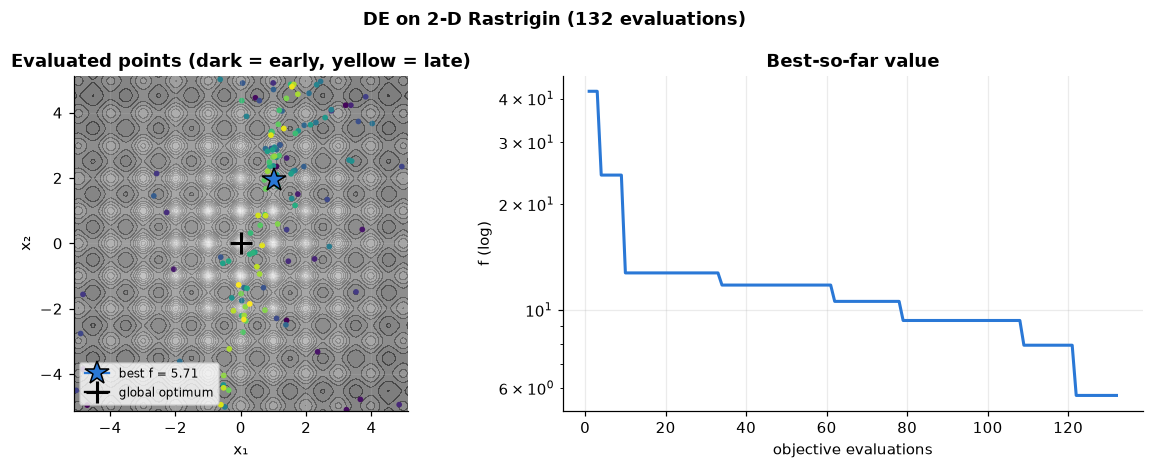

In [3]:
plot_search(DifferentialEvolution, budget(KEY, 12, 10), COLOR, title="DE on 2-D Rastrigin (132 evaluations)")

## 2. Hyper-parameter study

**Test case:** PID on the 3rd-order plant — cheap to simulate, and sensitive enough to show differences.
Budget ≈60 evaluations, 3 seeds per setting; the heat-map shows **mean J** (± std), best setting outlined.

### 2a. F × CR

27 runs in 46 s


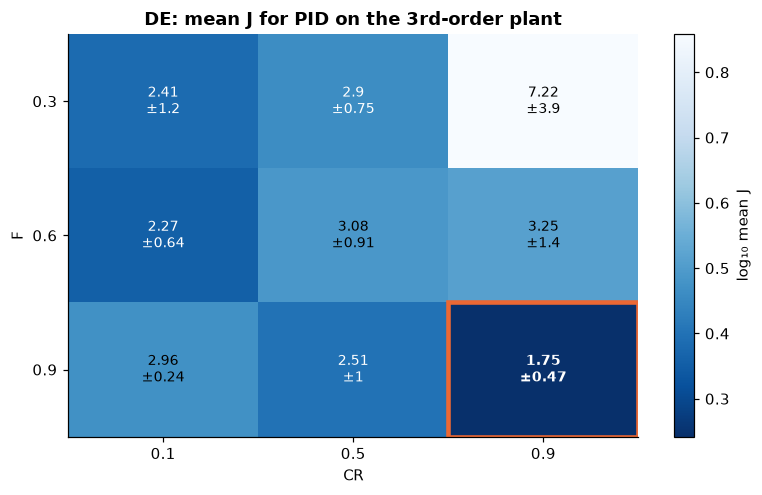

Best: F = 0.9, CR = 0.9  ->  mean J = 1.746
Worst/best ratio: 4.1x


In [4]:
ROWS, COLS = [0.3, 0.6, 0.9], [0.1, 0.5, 0.9]
mean, std = sweep2d(DifferentialEvolution, budget(KEY, 10, 5), 'mutation_factor', ROWS, 'crossover_rate', COLS)
i, j = sweep_heatmap(mean, ROWS, COLS, "F", "CR",
                     "DE: mean J for PID on the 3rd-order plant", std=std)
print(f"Best: F = {ROWS[i]}, CR = {COLS[j]}  ->  mean J = {mean[i, j]:.4g}")
print(f"Worst/best ratio: {mean.max() / mean.min():.1f}x")

### 2b. strategy

`rand1` explores from random bases; `best1` always mutates around the current best — faster but greedier.

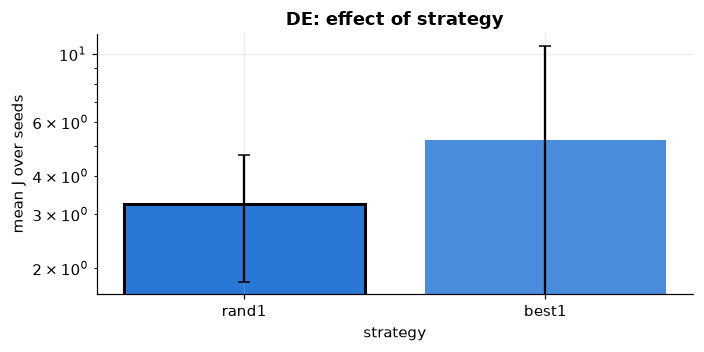

strategy =  rand1   mean J = 3.252 ± 1.4
strategy =  best1   mean J = 5.265 ± 5.4


In [5]:
VALUES = ['rand1', 'best1']
m1, s1 = sweep1d(DifferentialEvolution, budget(KEY, 10, 5), 'strategy', VALUES)
plot_sweep1d(VALUES, m1, s1, "strategy", COLOR, "DE: effect of strategy")
for v, m, sd in zip(VALUES, m1, s1):
    print(f"strategy = {v!s:>6}   mean J = {m:.4g} ± {sd:.2g}")

## 3. Population vs generations at a fixed budget

Every split below costs exactly **120 evaluations** (P × (1 + G)). Few large generations explore more;
many small generations exploit more. PID on the 3rd-order plant, 3 seeds.

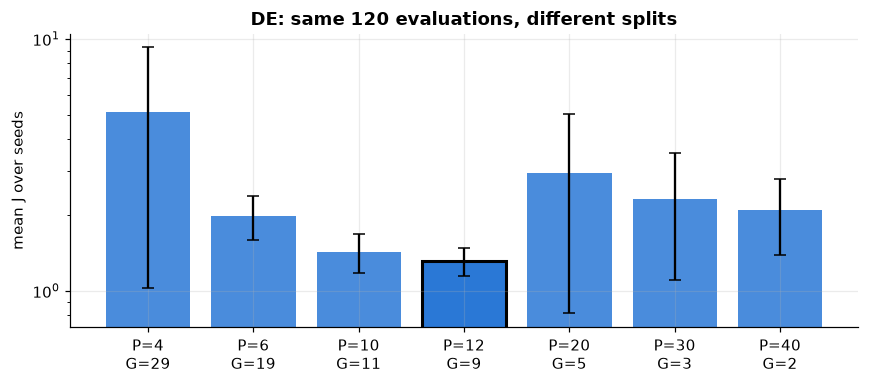

P =  4, G = 29   mean J = 5.141 ± 4.1
P =  6, G = 19   mean J = 1.988 ± 0.4
P = 10, G = 11   mean J = 1.425 ± 0.25
P = 12, G =  9   mean J = 1.313 ± 0.16
P = 20, G =  5   mean J = 2.934 ± 2.1
P = 30, G =  3   mean J = 2.311 ± 1.2
P = 40, G =  2   mean J = 2.088 ± 0.7


In [6]:
SPLITS = [(4, 29), (6, 19), (10, 11), (12, 9), (20, 5), (30, 3), (40, 2)]
means, stds = [], []
for p, g in SPLITS:
    js = [run(DifferentialEvolution, "PID", "third_order", budget(KEY, p, g), seed)["best_fitness"] for seed in (42, 43, 44)]
    means.append(np.mean(js)); stds.append(np.std(js))
plot_budget_split(SPLITS, means, stds, COLOR, "DE: same 120 evaluations, different splits")
for (p, g), m, sd in zip(SPLITS, means, stds):
    print(f"P = {p:2d}, G = {g:2d}   mean J = {m:.4g} ± {sd:.2g}")

## 4. Every controller on every plant

The real question: **how does DE do on the actual tuning problems?**

* Budget: population 10 × 5 generations ⇒ **≈60 objective evaluations per run** (the *Extended* budget used in the final system).
* Hyper-parameters: the **implementation defaults** (so these numbers match the final system), not the sweep winners above.
* 3 independent seeds (42, 43, 44) per cell → 4 controllers × 3 plants × 3 seeds = 36 runs.
* Fuzzy runs dominate the runtime (25-rule inference at every simulation step).

In [7]:
records = run_matrix(DifferentialEvolution, list(CONTROLLERS), PLANT_NAMES, budget(KEY, 10, 5), seeds=(42, 43, 44))

PID             2nd order seed 42  J =    0.6353  IAE =   0.447  settled = yes  (1.9 s)


PID             2nd order seed 43  J =     1.357  IAE =   0.284  settled = yes  (1.6 s)


PID             2nd order seed 44  J =    0.9374  IAE =   0.342  settled = yes  (1.7 s)


PID             3rd order seed 42  J =     1.252  IAE =   0.584  settled = yes  (1.6 s)


PID             3rd order seed 43  J =     3.888  IAE =   0.935  settled = yes  (2.0 s)


PID             3rd order seed 44  J =     4.617  IAE =   0.619  settled = yes  (1.9 s)


... (26 outputs left out)

GP Controller   3rd order seed 44  J =      28.7  IAE =    4.58  settled = no   (1.1 s)


GP Controller   4th order seed 42  J =        33  IAE =    8.66  settled = no   (1.5 s)


GP Controller   4th order seed 43  J =        33  IAE =    8.66  settled = no   (1.4 s)


GP Controller   4th order seed 44  J =        33  IAE =    8.66  settled = no   (1.1 s)

36 runs in 329 s


### Results table
J is mean ± std over seeds; the metric columns are from the best seed.

In [8]:
summary_table(records)

Controller      Plant        J mean    ± std  settled     IAE  Ts (s)  Tr (s)    OS %      Ess
----------------------------------------------------------------------------------------------
PID             2nd order    0.9766    0.296     3/3   0.447     0.6   0.366       0  0.00836
PID             3rd order     3.252     1.45     3/3   0.584    2.22   0.881       0  0.00202
PID             4th order     111.7     89.9     1/3    3.37    12.7    2.05    24.3   0.0017
Neural Network  2nd order      30.1    0.762     0/3    5.16       —    1.01       0     0.23
Neural Network  3rd order     31.54     5.66     1/3    14.8      20    3.72    4.32    0.623
Neural Network  4th order     42.05     6.19     0/3    12.5       —       —       0    0.583
Fuzzy           2nd order    0.8833   0.0522     3/3   0.532    0.99   0.782  0.0071  0.00117
Fuzzy           3rd order     1.742    0.143     3/3   0.674    3.18   0.802       0  0.00965
Fuzzy           4th order     28.54     5.92     2/3    7.

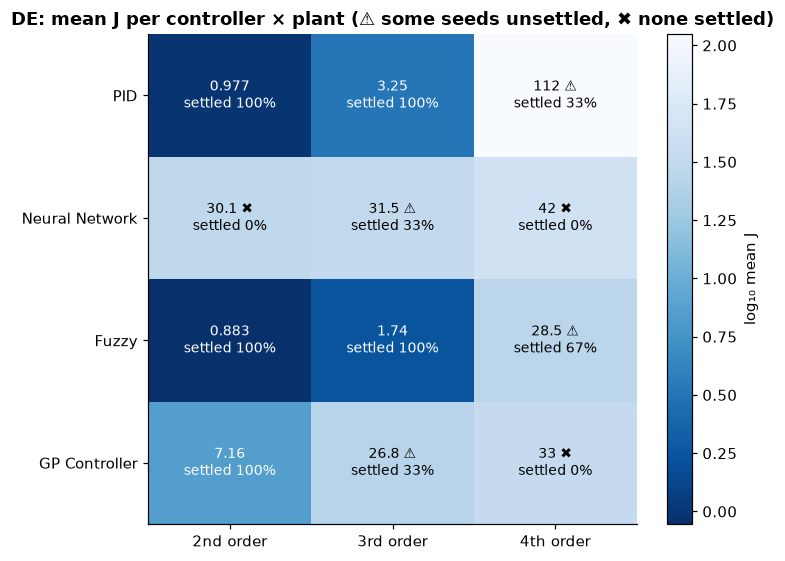

In [9]:
plot_matrix_heatmap(records, "DE: mean J per controller × plant (⚠ some seeds unsettled, ✖ none settled)")

### Step responses (best seed of each cell)

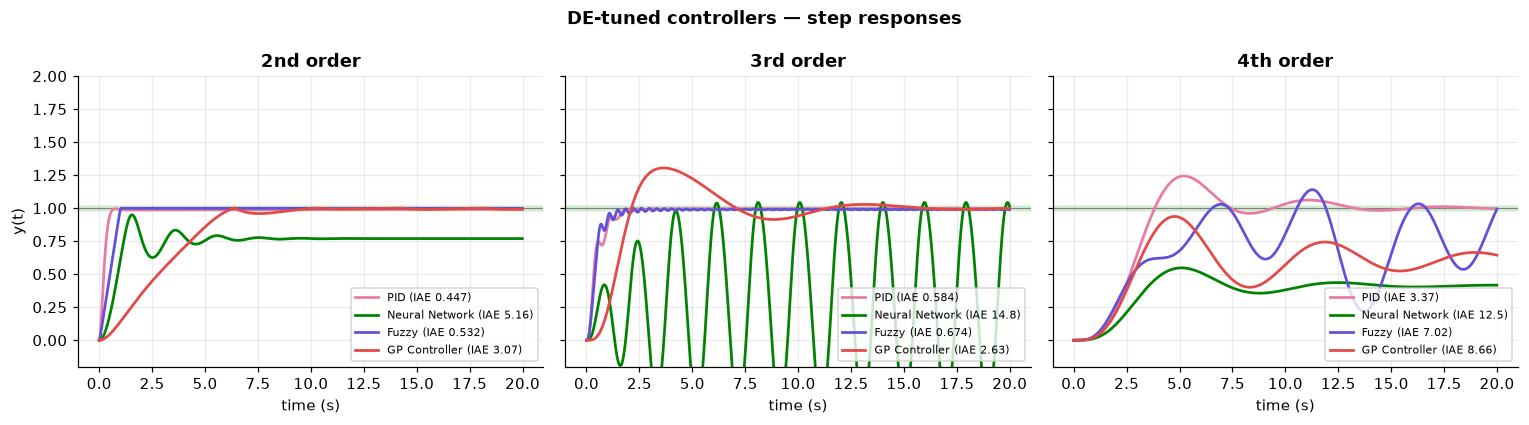

In [10]:
plot_step_grid(records, "DE-tuned controllers — step responses")

### Convergence
One line per seed; solid = 2nd, dashed = 3rd, dotted = 4th order.

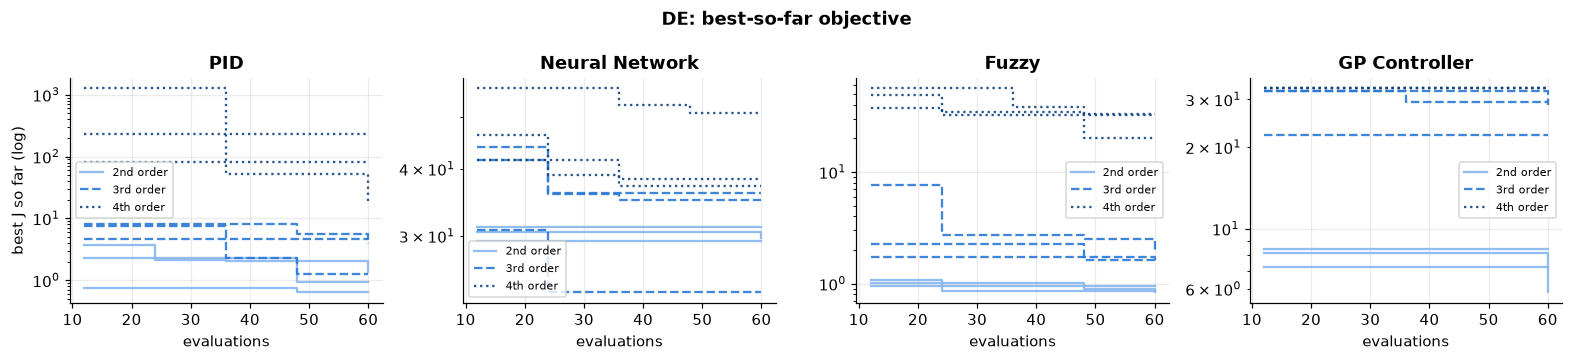

In [11]:
plot_convergence_grid(records, COLOR, "DE: best-so-far objective")

### Control effort on the 3rd-order plant
A good response is not enough if the actuator has to work unreasonably hard.

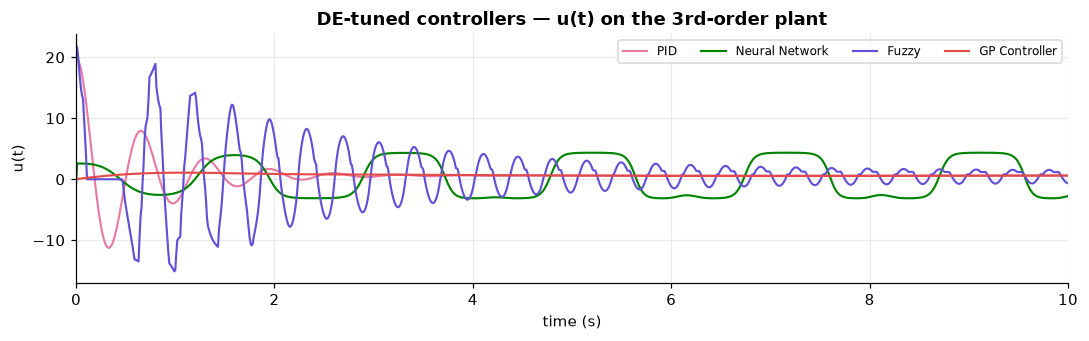

In [12]:
plot_control_effort(records, "third_order", "DE-tuned controllers — u(t) on the 3rd-order plant")

## Takeaways

**1. It works — but dimension hurts.** DE solves 2-D problems almost exactly (Sphere ≈ 1e-6, Rosenbrock ≈ 0.009) but with ≈500 evaluations it is far from the optimum in 10-D (Sphere ≈ 3.0, Rastrigin ≈ 60). The search plot shows why: the population is still spread over several Rastrigin basins after 132 evaluations — DE explores a lot before it commits.

**2. Hyper-parameters matter (4× spread in J).** On PID / 3rd order the best setting was **F = 0.9, CR = 0.9** (J ≈ 1.75); the worst, F = 0.3 with CR = 0.9, was 4× worse. With only ≈60 evaluations, large difference steps and heavy crossover (move fast, change many genes) pay off. **`rand1` beat `best1`** (J 3.25 vs 5.27, and `best1` had a much larger seed spread) — greedily mutating around the current best gets trapped.

**3. Budget split:** a population that is too small fails badly (P = 4: J ≈ 5.1 ± 4.1); **P ≈ 10–12 with ≈10 generations** was best (J ≈ 1.3–1.4, smallest spread). Very large populations waste the budget on generation 0.

**4. On the real problems (≈60 evals, defaults):**
- **PID and Fuzzy are tuned well on the 2nd- and 3rd-order plants** (all seeds settle; PID 3rd order J ≈ 3.3, Fuzzy ≈ 1.7).
- **PID on the 4th-order plant mostly fails** (1/3 seeds settle, J ≈ 112 ± 90) — the [0, 50] gain bounds are mostly *unstable* for this plant, so most of the budget is spent on diverging candidates.
- **The neural network almost never settles** (1/9 runs): 21 parameters is too many for 60 evaluations.
- **The GP controller** settles on the 2nd-order plant only; on the 4th-order plant every seed lands on J = 33.0 — a degenerate constant-output law (see Study 05).
- Fuzzy runs cost ~30 s each vs ~2 s for PID — inference cost, not DE, dominates the runtime.

**Implications for the full system:** DE needs either more evaluations or larger F/CR than the defaults (0.6/0.9) under a tight budget; the 4th-order PID failure points at the parameter bounds rather than at DE itself.